# Task 2: detailed OOF error audit

Analyze cached predictions from the original and weighted CatBoost models on the same five development folds. Holdout and Test are not used for selecting slices. This creates no dataset or model artifact. Group associations are diagnostic, not proof of causation or leakage.

In [1]:
from pathlib import Path
from hashlib import sha256
import json,sys
ROOT=next(x for x in (Path.cwd(),*Path.cwd().parents) if (x/'src'/'pipeline'/'save_data.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
SRC=ROOT/'src'
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.metrics import classification_report,confusion_matrix,f1_score
from src.pipeline.random_seed import set_seed
SEED=set_seed()
DATA='eda_original_v2';BASE='t2_cat_original_no_noise_v2';WEIGHTED='t2_cat_weighted_23_cv5_v4'
dcard=json.loads((SRC/'task2'/'data'/'eda'/f'{DATA}.json').read_text(encoding='utf8'))
bcard=json.loads((SRC/'task2'/'save'/f'{BASE}.json').read_text(encoding='utf8'))
wcard=json.loads((SRC/'task2'/'save'/f'{WEIGHTED}.json').read_text(encoding='utf8'))
assert bcard['data_name']==wcard['data_name']==DATA
train=pd.read_parquet(SRC/dcard['splits']['train']['path'])
assert train.player_id.is_unique and len(train)==104000 and train.segment.notna().all()
y=train.segment.astype(int)
dev_idx,valid_idx=train_test_split(np.arange(len(y)),test_size=.2,stratify=y,random_state=SEED)
dev=train.iloc[dev_idx].reset_index(drop=True)
folds=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(dev,dev.segment))
signature=sha256(np.asarray(dev_idx,dtype=np.int64).tobytes()+np.asarray(y.iloc[dev_idx],dtype=np.int8).tobytes()).hexdigest()
key={'data_name':DATA,'data_created_at':dcard['created_at'],'model_name':BASE,
     'model_created_at':bcard['created_at'],'seed':SEED,'folds':5,'split_signature':signature}
results=SRC/'task2'/'models'/'results'
def load_oof(stem,version,expected_key):
    parts=[]
    for fold,(_,check) in enumerate(folds,1):
        path=results/f'{stem}_fold{fold}_v{version}.parquet'
        meta=json.loads(path.with_suffix('.json').read_text(encoding='utf8'))
        assert meta=={'key':expected_key,'fold':fold}
        part=pd.read_parquet(path)
        assert part.row_pos.tolist()==check.tolist()
        assert part.true.tolist()==dev.segment.iloc[check].tolist()
        parts.append(part)
    part=pd.concat(parts).sort_values('row_pos').reset_index(drop=True)
    assert part.row_pos.tolist()==list(range(len(dev)))
    prob=part[[f'p_{i}' for i in range(4)]].to_numpy(float)
    assert np.isfinite(prob).all() and np.allclose(prob.sum(1),1,atol=1e-5)
    part['pred']=prob.argmax(1)
    part['pmax']=prob.max(1)
    part['margin']=np.sort(prob,axis=1)[:,-1]-np.sort(prob,axis=1)[:,-2]
    part['correct']=part.true==part.pred
    return part
base=load_oof('class_bias',1,key)
weighted=load_oof('weighted_23',4,{**key,'experiment':WEIGHTED,'weights':[1.,1.,1.25,1.25]})
assert base.true.equals(weighted.true)
D=dev.join(base[['pred','pmax','margin','correct']].add_prefix('base_'))
D=D.join(weighted[['pred','pmax','margin','correct']].add_prefix('weighted_'))
labels=['Casual','Grinder','Social','Whale']
print('Rows:',len(D),'raw predictors:',len(dev.columns)-2)
print('OOF macro F1 baseline/weighted:',
      f1_score(base.true,base.pred,average='macro'),
      f1_score(weighted.true,weighted.pred,average='macro'))

Rows: 83200 raw predictors: 44
OOF macro F1 baseline/weighted: 0.7525700687982839 0.7531042348686483


## 1. Error directions and model confidence

              precision    recall  f1-score   support

      Casual     0.7841    0.8626    0.8215     32766
     Grinder     0.7491    0.7335    0.7412     20825
      Social     0.7449    0.6782    0.7100     16823
       Whale     0.7810    0.6988    0.7376     12786

    accuracy                         0.7678     83200
   macro avg     0.7647    0.7433    0.7526     83200
weighted avg     0.7669    0.7678    0.7660     83200



,pred Casual,pred Grinder,pred Social,pred Whale
true Casual,28265,2779,1525,197
true Grinder,4098,15275,570,882
true Social,3155,831,11410,1427
true Whale,531,1507,1813,8935


,error pair,rows
0,Grinder → Casual,4098
1,Social → Casual,3155
2,Casual → Grinder,2779
3,Whale → Social,1813
4,Casual → Social,1525
5,Whale → Grinder,1507
6,Social → Whale,1427
7,Grinder → Whale,882
8,Social → Grinder,831
9,Grinder → Social,570


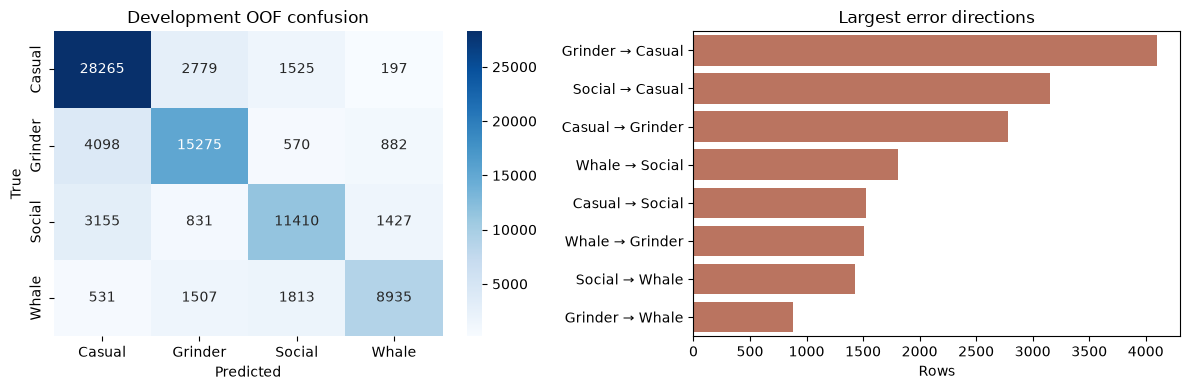

,rows,errors,median_margin,error_rate
confidence_bin,,,,
"(-0.001, 0.4]",2889,1747,0.051426,0.604708
"(0.4, 0.5]",7093,3563,0.101814,0.502326
"(0.5, 0.6]",12124,5003,0.198228,0.412653
"(0.6, 0.7]",12114,3725,0.383602,0.307495
"(0.7, 0.8]",13093,2555,0.563329,0.195142
"(0.8, 0.9]",16127,1811,0.742743,0.112296
"(0.9, 1.0]",19760,911,0.910131,0.046103


Wrong rows: 19315 wrong with Pmax > .8: 2722
Median Pmax correct/wrong: {False: 0.5849834544222621, True: 0.8097501003317623}
Median margin correct/wrong: {False: 0.2769770599378135, True: 0.6670356325029078}


,,rows,median_pmax,high_conf,high_conf_share
segment,base_pred,,,,
1,0,4098,0.618342,723,0.176428
2,0,3155,0.605377,516,0.163550
0,1,2779,0.589308,331,0.119108
3,2,1813,0.593254,242,0.133480
0,2,1525,0.538036,86,0.056393
3,1,1507,0.574837,164,0.108825
2,3,1427,0.593229,203,0.142256
1,3,882,0.546205,85,0.096372
2,1,831,0.484159,83,0.099880


In [2]:
cm=confusion_matrix(base.true,base.pred,labels=range(4))
off=cm.copy();np.fill_diagonal(off,0)
pairs=sorted([(labels[i]+' → '+labels[j],int(off[i,j])) for i in range(4) for j in range(4) if i!=j],
             key=lambda z:z[1],reverse=True)
print(classification_report(base.true,base.pred,target_names=labels,digits=4))
display(pd.DataFrame(cm,index=['true '+x for x in labels],columns=['pred '+x for x in labels]))
display(pd.DataFrame(pairs,columns=['error pair','rows']))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=labels,yticklabels=labels,ax=ax[0])
ax[0].set(xlabel='Predicted',ylabel='True',title='Development OOF confusion')
sns.barplot(x=[v for _,v in pairs[:8]],y=[k for k,_ in pairs[:8]],ax=ax[1],color='#C96B51')
ax[1].set(xlabel='Rows',title='Largest error directions')
plt.tight_layout();plt.show()
D['confidence_bin']=pd.cut(D.base_pmax,[0,.4,.5,.6,.7,.8,.9,1.000001],include_lowest=True)
conf=D.groupby('confidence_bin',observed=True).agg(rows=('segment','size'),
    errors=('base_correct',lambda s:int((~s).sum())),median_margin=('base_margin','median'))
conf['error_rate']=conf.errors/conf.rows
display(conf)
wrong=D[~D.base_correct]
print('Wrong rows:',len(wrong),'wrong with Pmax > .8:',int((wrong.base_pmax>.8).sum()))
print('Median Pmax correct/wrong:',D.groupby('base_correct').base_pmax.median().to_dict())
print('Median margin correct/wrong:',D.groupby('base_correct').base_margin.median().to_dict())
pair_conf=D[~D.base_correct].groupby(['segment','base_pred']).agg(
    rows=('segment','size'),median_pmax=('base_pmax','median'),
    high_conf=('base_pmax',lambda s:int((s>.8).sum())))
pair_conf['high_conf_share']=pair_conf.high_conf/pair_conf.rows
display(pair_conf.sort_values('rows',ascending=False).head(12))

## 2. Profiles of the largest confusion groups

Each comparison stays inside the true class: correct rows versus a specified wrong prediction. Numeric values are medians; category tables use at least 100 rows per level. These are descriptive patterns.

In [3]:
groups={
    (2,0):['friend_count','team_play_percentage','chat_activity_score',
           'gifts_sent_received','item_type_preference_social','play_frequency'],
    (3,2):['total_spending_thb','avg_monthly_spending','spending_frequency',
           'vip_tier','friend_count','item_type_preference_social'],
    (1,0):['ranked_participation_rate','competitive_rank','login_streak',
           'achievement_completion_rate','play_frequency']}
for (actual,pred),cols in groups.items():
    sub=D[D.segment==actual].copy()
    sub['group']=np.where(sub.base_pred==actual,'correct',
                          np.where(sub.base_pred==pred,f'pred {labels[pred]}','other error'))
    selection=sub[sub.group.isin(['correct',f'pred {labels[pred]}'])]
    print(f'{labels[actual]} → {labels[pred]}:',sub.group.value_counts().to_dict())
    display(selection.groupby('group')[cols].median().T)
for actual,pred in [(2,0),(3,2)]:
    sub=D[D.segment==actual].copy()
    sub['pair_error']=sub.base_pred==pred
    print('Category rates for',labels[actual],'→',labels[pred])
    for col in ['player_type_tag','engagement_level','loyalty_tier','skill_tier']:
        tab=sub.assign(level=sub[col].fillna('<missing>').astype(str)).groupby('level').agg(
            rows=('segment','size'),pair_errors=('pair_error','sum'))
        tab=tab[tab.rows>=100].copy()
        tab['pair_error_rate']=tab.pair_errors/tab.rows
        print(col);display(tab.sort_values('pair_error_rate',ascending=False).head(8))

Social → Casual: {'correct': 11410, 'pred Casual': 3155, 'other error': 2258}


group,correct,pred Casual
friend_count,86.000000,85.000000
team_play_percentage,48.713908,48.830478
chat_activity_score,54.783269,53.903595
gifts_sent_received,71.000000,68.000000
item_type_preference_social,0.502753,0.502076
play_frequency,9.932980,9.550718


Whale → Social: {'correct': 8935, 'other error': 2038, 'pred Social': 1813}


group,correct,pred Social
total_spending_thb,48378.219819,42212.492726
avg_monthly_spending,4813.295159,4369.085065
spending_frequency,24.733254,21.744881
vip_tier,2.000000,2.000000
friend_count,133.000000,103.500000
item_type_preference_social,0.497959,0.483666


Grinder → Casual: {'correct': 15275, 'pred Casual': 4098, 'other error': 1452}


group,correct,pred Casual
ranked_participation_rate,51.476628,50.953355
competitive_rank,5.000000,5.000000
login_streak,65.000000,49.500000
achievement_completion_rate,50.835417,49.674141
play_frequency,14.289032,10.963338


... (12 outputs left out)

loyalty_tier


,rows,pair_errors,pair_error_rate
level,,,
Diamond,2273,419,0.184338
Platinum,3367,596,0.177012
Gold,3499,538,0.153758
<missing>,948,103,0.108650
Silver,2447,157,0.064160
Bronze,252,0,0.000000


skill_tier


,rows,pair_errors,pair_error_rate
level,,,
<missing>,1027,155,0.150925
Bronze,2901,433,0.149259
Silver,2958,426,0.144016
Platinum,1769,244,0.137931
Diamond,1752,240,0.136986
Gold,2379,315,0.132409


## 3. Exact feature conflicts and missingness

Check identical supplied model inputs after excluding player ID, target and the three documented random metrics. Identical features with different labels indicate an unavoidable conflict for a deterministic classifier. No exact conflicts does not rule out near overlap.

In [4]:
used=[x for x in dev.columns if x not in
      ('player_id','segment','random_metric_1','random_metric_2','random_metric_3')]
assert len(used)==41
hashes=pd.util.hash_pandas_object(dev[used],index=False)
same=pd.DataFrame({'hash':hashes,'label':dev.segment}).groupby('hash').agg(
    rows=('label','size'),labels=('label','nunique'))
duplicate=same[same.rows>1];conflict=duplicate[duplicate.labels>1]
print('Duplicate fingerprints:',len(duplicate),'rows:',int(duplicate.rows.sum()))
print('Different-label fingerprints:',len(conflict),'rows:',int(conflict.rows.sum()))
missing=dev[used].isna().sum(axis=1)
display(pd.DataFrame({'missing':missing,'error':~D.base_correct}).groupby('missing').agg(
    rows=('error','size'),error_rate=('error','mean')).head(20))

Duplicate fingerprints: 0 rows: 0
Different-label fingerprints: 0 rows: 0


,rows,error_rate
missing,,
0,1910,0.203141
1,7609,0.226574
2,14799,0.225150
3,18518,0.227022
4,16813,0.234937
5,11836,0.237073
6,6701,0.243098
7,3190,0.248903
8,1230,0.269919


## 4. What did weighting rescue and break?

In [5]:
change=pd.DataFrame({'true':D.segment,'base':D.base_pred,'weighted':D.weighted_pred,
                     'base_ok':D.base_correct,'weighted_ok':D.weighted_correct})
change['outcome']=np.select([change.base_ok&change.weighted_ok,
    (~change.base_ok)&change.weighted_ok,change.base_ok&(~change.weighted_ok)],
    ['both correct','rescued','broken'],default='both wrong')
display(pd.crosstab(change.true.map(dict(enumerate(labels))),change.outcome))
print('Prediction switches:',int((change.base!=change.weighted).sum()))
print('Rescued/broken:',int((change.outcome=='rescued').sum()),int((change.outcome=='broken').sum()))
display(pd.DataFrame({'class':labels,
    'baseline_F1':f1_score(change.true,change.base,average=None,labels=[0,1,2,3]),
    'weighted_F1':f1_score(change.true,change.weighted,average=None,labels=[0,1,2,3])}))

outcome,both correct,both wrong,broken,rescued
true,,,,
Casual,27659,4383,606,118
Grinder,14855,5401,420,149
Social,11316,4845,94,568
Whale,8832,3532,103,319


Prediction switches: 2815
Rescued/broken: 1154 1223


,class,baseline_F1,weighted_F1
0,Casual,0.821478,0.820118
1,Grinder,0.741199,0.739678
2,Social,0.709997,0.712128
3,Whale,0.737607,0.740492


## 5. Why do the tier fields dominate?

Inspect class composition for loyalty and engagement jointly, plus the baseline model's feature importance. The datacard does not state when these derived tiers were created, so strong target association alone is not evidence of leakage.

In [6]:
import joblib
model=joblib.load(SRC/bcard['model_path'])
pre=model.named_steps['preprocess']
importance=pd.Series(model.named_steps['classifier'].feature_importances_,
                     index=pre.get_feature_names_out()).sort_values(ascending=False)
display(importance.head(20).rename('CatBoost importance').to_frame())
for col in ['loyalty_tier','engagement_level','vip_tier','player_type_tag']:
    levels=dev[col].astype('object').fillna('<missing>').astype(str)
    print(col,'class proportion per level')
    display(pd.crosstab(levels,dev.segment,normalize='index').round(3))
    print('level counts:',levels.value_counts().to_dict())
loyal=dev.loyalty_tier.fillna('<missing>')
engage=dev.engagement_level.fillna('<missing>')
combo=pd.crosstab([loyal,engage],dev.segment)
combo=combo[combo.sum(1)>=100]
display((combo.div(combo.sum(1),axis=0).round(3)).assign(rows=combo.sum(1)))
print('Spending medians by loyalty tier:')
display(dev.groupby('loyalty_tier',dropna=False)[
    ['total_spending_thb','avg_monthly_spending','spending_frequency']].median().round(1))

,CatBoost importance
categorical__loyalty_tier,31.850079
categorical__engagement_level,10.614478
numeric__vip_tier,6.500642
numeric__days_since_last_login,4.851523
numeric__avg_monthly_spending,4.406549
numeric__spending_frequency,4.343039
numeric__rare_items_count,3.383948
numeric__total_spending_thb,3.095316
numeric__total_playtime_hours,3.052593
numeric__friend_count,2.685951


loyalty_tier

 class proportion per level


segment,0,1,2,3
loyalty_tier,,,,
<missing>,0.398,0.256,0.197,0.148
Bronze,0.598,0.382,0.010,0.010
Diamond,0.007,0.009,0.558,0.425
Gold,0.234,0.151,0.349,0.267
Platinum,0.011,0.011,0.560,0.418
Silver,0.477,0.297,0.129,0.097


level counts: {'Silver': 25211, 'Bronze': 25061, 'Gold': 13127, 'Platinum': 8057, '<missing>': 6401, 'Diamond': 5343}
engagement_level class proportion per level


segment,0,1,2,3
engagement_level,,,,
<missing>,0.394,0.250,0.205,0.152
High,0.185,0.449,0.092,0.274
Low,0.574,0.080,0.296,0.050
Mid,0.394,0.251,0.202,0.153
Veteran,0.010,0.600,0.010,0.379


... (5 outputs left out)

C:\Users\BTCOM\AppData\Local\Temp\ipykernel_43788\145957217.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  combo=combo[combo.sum(1)>=100]
C:\Users\BTCOM\AppData\Local\Temp\ipykernel_43788\145957217.py:16: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  display((combo.div(combo.sum(1),axis=0).round(3)).assign(rows=combo.sum(1)))
C:\Users\BTCOM\AppData\Local\Temp\ipykernel_43788\145957217.py:16: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  display((combo.div(combo.sum(1),axis=0).round(3)).assign(rows=combo.sum(1)))


segment                            0      1      2      3  rows
loyalty_tier engagement_level                                  
<missing>    <missing>         0.381  0.258  0.212  0.149   504
             High              0.175  0.461  0.089  0.275  1330
             Low               0.585  0.082  0.285  0.049  2028
             Mid               0.401  0.258  0.195  0.146  2333
             Veteran           0.015  0.626  0.029  0.330   206
Bronze       <missing>         0.602  0.379  0.011  0.008  1987
             High              0.281  0.701  0.007  0.012  4989
             Low               0.864  0.116  0.010  0.010  7912
             Mid               0.599  0.380  0.011  0.010  9269
             Veteran           0.009  0.975  0.012  0.004   904
Diamond      <missing>         0.010  0.002  0.550  0.438   420
             High              0.011  0.005  0.234  0.750  1110
             Low               0.010  0.012  0.843  0.136  1641
             Mid               0.004  0.010  0.557  0.430  1984
             Veteran           0.005  0.021  0.011  0.963   188
Gold         <missing>         0.223  0.149  0.367  0.261   989
             High              0.112  0.266  0.162  0.459  2722
             Low               0.347  0.056  0.513  0.084  4053
             Mid               0.233  0.150  0.350  0.268  4837
             Veteran           0.008  0.317  0.002  0.673   526
Platinum     <missing>         0.017  0.011  0.541  0.431   640
             High              0.011  0.011  0.240  0.738  1730
             Low               0.012  0.010  0.858  0.121  2431
             Mid               0.010  0.011  0.568  0.411  2926
             Veteran           0.015  0.006  0.015  0.964   330
Silver       <missing>         0.477  0.298  0.134  0.091  1966
             High              0.230  0.543  0.057  0.170  5012
             Low               0.688  0.093  0.188  0.031  7964
             Mid               0.475  0.299  0.126  0.099  9363
             Veteran           0.012  0.720  0.008  0.260   906

Spending medians by loyalty tier:


,total_spending_thb,avg_monthly_spending,spending_frequency
loyalty_tier,,,
Bronze,26696.0,2633.7,13.7
Diamond,40982.3,4119.3,21.5
Gold,35663.4,3625.2,18.4
Platinum,42153.9,4096.2,21.3
Silver,30053.2,2968.3,15.1
NaN,32089.4,3151.4,16.3


## Interpretation

Use the executed tables to locate error concentrations and assess whether ambiguous or confident mistakes dominate. This analysis does not choose a new model or claim a competition score.